Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 39, 861, 16)    │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 19, 430, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 19, 430, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 18, 429, 32)    │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 9, 214, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 9, 214, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 213, 64)     │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 106, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 106, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 3, 105, 128)    │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 1, 52, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1, 52, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 43,312 (169.19 KB)

 Trainable params: 43,312 (169.19 KB)

 Non-trainable params: 0 (0.00 B)

23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


C:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Ensemble Test Accuracy: 0.8913
Classification Report:
                precision    recall  f1-score   support

Bronchiectasis       1.00      0.67      0.80         3
 Bronchiolitis       0.00      0.00      0.00         3
          COPD       0.94      0.99      0.97       159
       Healthy       0.29      0.29      0.29         7
     Pneumonia       0.50      0.14      0.22         7
          URTI       0.33      0.20      0.25         5

      accuracy                           0.89       184
     macro avg       0.51      0.38      0.42       184
  weighted avg       0.87      0.89      0.87       184

Confusion Matrix:
[[  2   0   0   1   0   0]
 [  0   0   0   1   0   2]
 [  0   0 158   1   0   0]
 [  0   2   3   2   0   0]
 [  0   0   6   0   1   0]
 [  0   0   1   2   1   1]]


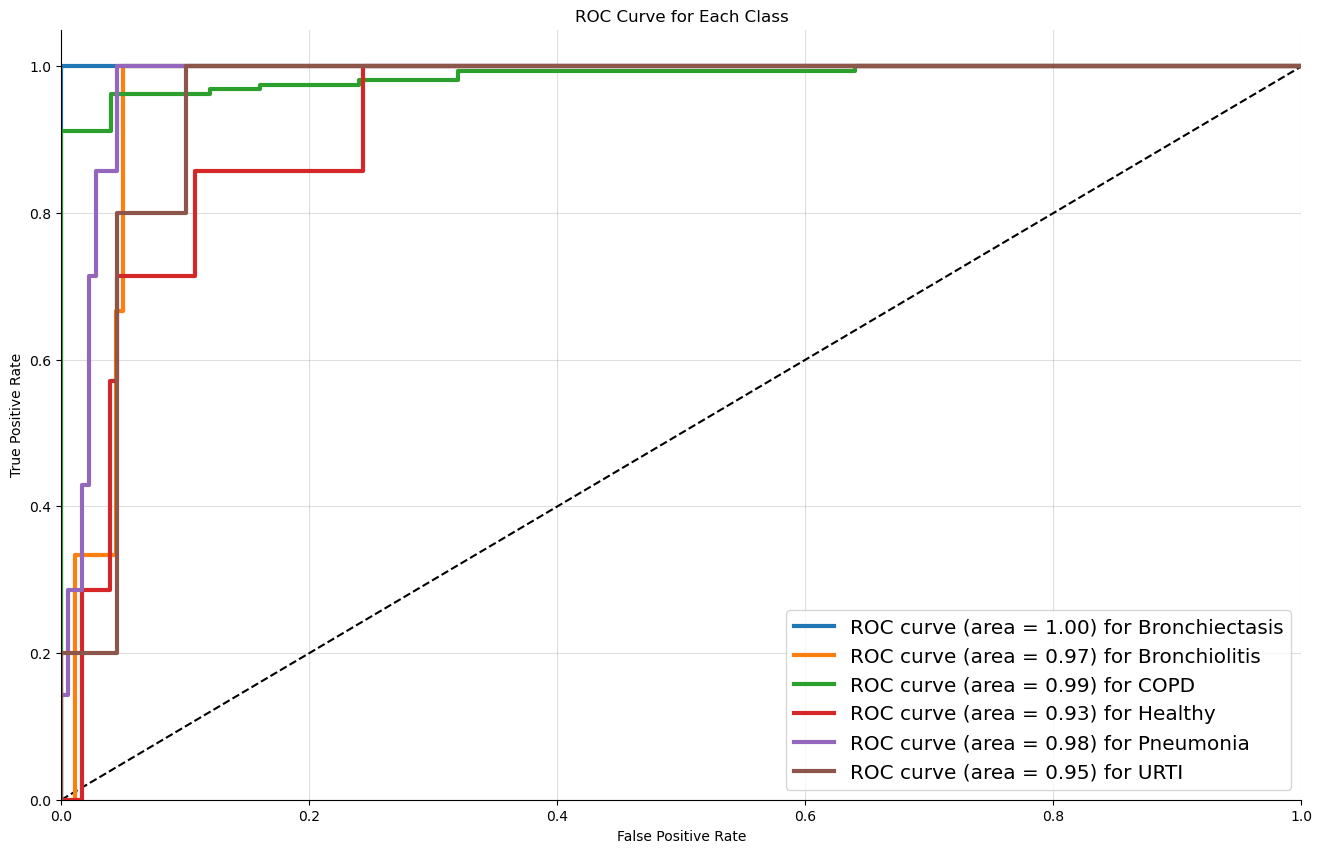

In [1]:
import numpy as np
import pandas as pd
import librosa
from datetime import datetime
from os import listdir
from os.path import isfile, join
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Conv2D, MaxPooling2D, GlobalAveragePooling2D, Input
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import VotingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
import matplotlib.pyplot as plt
import seaborn as sns

# File paths and loading data
mypath = "E:\\FFF\\respiratory-sound-database\\Respiratory_Sound_Database\\Respiratory_Sound_Database\\audio_and_txt_files\\"
filenames = [f for f in listdir(mypath) if (isfile(join(mypath, f)) and f.endswith('.wav'))]
p_id_in_file = [int(name[:3]) for name in filenames]
p_id_in_file = np.array(p_id_in_file)
max_pad_len = 862

# Feature extraction function
def extract_features(file_name):
    try:
        audio, sample_rate = librosa.load(file_name, res_type='kaiser_fast', duration=20)
        mfccs = librosa.feature.mfcc(y=audio, sr=sample_rate, n_mfcc=40)
        pad_width = max_pad_len - mfccs.shape[1]
        mfccs = np.pad(mfccs, pad_width=((0, 0), (0, pad_width)), mode='constant')
    except Exception as e:
        print(f"Error encountered while parsing file: {file_name}")
        print(f"Exception: {e}")
        return None 
    return mfccs

# Load file paths and labels
filepaths = [join(mypath, f) for f in filenames]
p_diag = pd.read_csv("E:\\FFF\\respiratory-sound-database\\Respiratory_Sound_Database\\Respiratory_Sound_Database\\patient_diagnosis.csv", header=None)
labels = np.array([p_diag[p_diag[0] == x][1].values[0] for x in p_id_in_file])

# Extract features
features = [extract_features(file_name) for file_name in filepaths]
features = np.array(features)

# Remove specific labels and convert labels
features1 = np.delete(features, np.where((labels == 'Asthma') | (labels == 'LRTI'))[0], axis=0)
labels1 = np.delete(labels, np.where((labels == 'Asthma') | (labels == 'LRTI'))[0], axis=0)

# One-hot encode labels
le = LabelEncoder()
i_labels = le.fit_transform(labels1)
oh_labels = to_categorical(i_labels)

# Reshape features for CNN
features1 = np.reshape(features1, (*features1.shape, 1))

# Train-test split
x_train, x_test, y_train, y_test = train_test_split(features1, oh_labels, stratify=oh_labels, test_size=0.2, random_state=42)

# Define CNN model for feature extraction
num_rows = 40
num_columns = 862
num_channels = 1
filter_size = 2

cnn_model = Sequential()
cnn_model.add(Input(shape=(num_rows, num_columns, num_channels)))
cnn_model.add(Conv2D(filters=16, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling2D(pool_size=2))
cnn_model.add(Dropout(0.2))
cnn_model.add(Conv2D(filters=32, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling2D(pool_size=2))
cnn_model.add(Dropout(0.2))
cnn_model.add(Conv2D(filters=64, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling2D(pool_size=2))
cnn_model.add(Dropout(0.2))
cnn_model.add(Conv2D(filters=128, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling2D(pool_size=2))
cnn_model.add(Dropout(0.2))
cnn_model.add(GlobalAveragePooling2D())

cnn_model.compile(loss='categorical_crossentropy', metrics=['accuracy'], optimizer='adam')
cnn_model.summary()

# Extract features using CNN
x_train_features = cnn_model.predict(x_train)
x_test_features = cnn_model.predict(x_test)

# Flatten the features for ensemble learning
x_train_features = x_train_features.reshape(x_train_features.shape[0], -1)
x_test_features = x_test_features.reshape(x_test_features.shape[0], -1)

# Convert one-hot labels to single integers
y_train = np.argmax(y_train, axis=1)
y_test = np.argmax(y_test, axis=1)

# Define base models for ensemble learning
model1 = RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42)
model2 = LogisticRegression(max_iter=1000, random_state=42)
model3 = SVC(kernel='linear', probability=True, random_state=42)

# Option 1: Voting Classifier
ensemble_model = VotingClassifier(
    estimators=[
        ('rf', model1),
        ('lr', model2),
        ('svc', model3)
    ],
    voting='soft'  # Use 'hard' for majority voting
)

# Option 2: Stacking Classifier
# ensemble_model = StackingClassifier(
#     estimators=[
#         ('rf', model1),
#         ('lr', model2),
#         ('svc', model3)
#     ],
#     final_estimator=LogisticRegression(max_iter=1000, random_state=42),
#     stack_method='auto'
# )

# Train the ensemble model
ensemble_model.fit(x_train_features, y_train)

# Evaluate the ensemble model
y_pred = ensemble_model.predict(x_test_features)
accuracy = accuracy_score(y_test, y_pred)
print(f"Ensemble Test Accuracy: {accuracy:.4f}")

# Classification Report and Confusion Matrix
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_, zero_division=1))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Plot ROC curves
fpr = dict()
tpr = dict()
roc_auc = dict()
y_test_onehot = to_categorical(y_test, num_classes=len(le.classes_))
y_pred_proba = ensemble_model.predict_proba(x_test_features)
for i in range(len(le.classes_)):
    fpr[i], tpr[i], _ = roc_curve(y_test_onehot[:, i], y_pred_proba[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# ROC Curve Plot
fig, ax = plt.subplots(figsize=(16, 10))
ax.plot([0, 1], [0, 1], 'k--')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve for Each Class')
for i in range(len(le.classes_)):
    ax.plot(fpr[i], tpr[i], linewidth=3, label='ROC curve (area = %0.2f) for %s' % (roc_auc[i], le.classes_[i]))
ax.legend(loc="best", fontsize='x-large')
ax.grid(alpha=.4)
sns.despine()
plt.show()

In [3]:
pip install numpy pandas librosa tensorflow scikit-learn matplotlib seaborn


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 39, 861, 16)    │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 19, 430, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 19, 430, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 18, 429, 32)    │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 9, 214, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 9, 214, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 8, 213, 64)     │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 4, 106, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 4, 106, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 3, 105, 128)    │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 1, 52, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 1, 52, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 43,312 (169.19 KB)

 Trainable params: 43,312 (169.19 KB)

 Non-trainable params: 0 (0.00 B)

23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
Ensemble Test Accuracy: 0.9022
Classification Report:
                precision    recall  f1-score   support

Bronchiectasis       1.00      0.67      0.80         3
 Bronchiolitis       0.00      0.00      0.00         3
          COPD       0.94      1.00      0.97       159
       Healthy       0.50      0.43      0.46         7
     Pneumonia       0.50      0.14      0.22         7
          URTI       0.33      0.20      0.25         5

      accuracy                           0.90       184
     macro avg       0.54      0.41      0.45       184
  weighted avg       0.87      0.90      0.88       184

Confusion Matrix:
[[  2   0   1   0   0   0]
 [  0   0   1   0   0   2]
 [  0   0 159   0   0   0]
 [  0   1   2   3   1   0]
 [  0   0   6   0   1   0]
 [  0   0   1   3   0   1]]


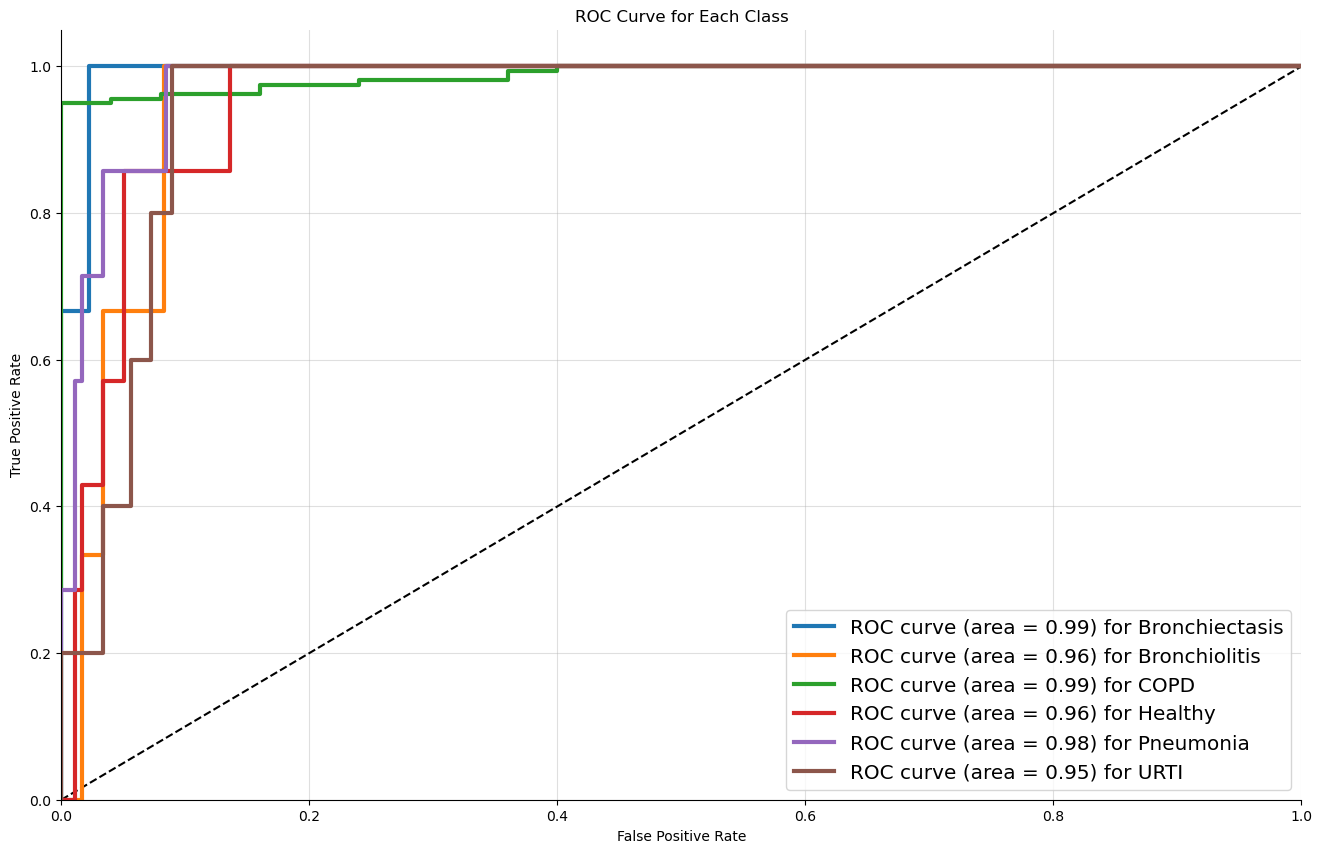

In [5]:
import numpy as np
import pandas as pd
import librosa
from datetime import datetime
from os import listdir
from os.path import isfile, join
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Conv2D, MaxPooling2D, GlobalAveragePooling2D, Input
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import VotingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
import matplotlib.pyplot as plt
import seaborn as sns

# File paths and loading data
mypath = "F:\\FFF\\respiratory-sound-database\\Respiratory_Sound_Database\\Respiratory_Sound_Database\\audio_and_txt_files\\"
filenames = [f for f in listdir(mypath) if (isfile(join(mypath, f)) and f.endswith('.wav'))]
p_id_in_file = [int(name[:3]) for name in filenames]
p_id_in_file = np.array(p_id_in_file)
max_pad_len = 862

# Feature extraction function
def extract_features(file_name):
    try:
        audio, sample_rate = librosa.load(file_name, res_type='kaiser_fast', duration=20)
        mfccs = librosa.feature.mfcc(y=audio, sr=sample_rate, n_mfcc=40)
        pad_width = max_pad_len - mfccs.shape[1]
        mfccs = np.pad(mfccs, pad_width=((0, 0), (0, pad_width)), mode='constant')
    except Exception as e:
        print(f"Error encountered while parsing file: {file_name}")
        print(f"Exception: {e}")
        return None 
    return mfccs

# Load file paths and labels
filepaths = [join(mypath, f) for f in filenames]
p_diag = pd.read_csv("F:\\FFF\\respiratory-sound-database\\Respiratory_Sound_Database\\Respiratory_Sound_Database/patient_diagnosis.csv", header=None)
labels = np.array([p_diag[p_diag[0] == x][1].values[0] for x in p_id_in_file])

# Extract features
features = [extract_features(file_name) for file_name in filepaths]
features = np.array(features)

# Remove specific labels and convert labels
features1 = np.delete(features, np.where((labels == 'Asthma') | (labels == 'LRTI'))[0], axis=0)
labels1 = np.delete(labels, np.where((labels == 'Asthma') | (labels == 'LRTI'))[0], axis=0)

# One-hot encode labels
le = LabelEncoder()
i_labels = le.fit_transform(labels1)
oh_labels = to_categorical(i_labels)

# Reshape features for CNN
features1 = np.reshape(features1, (*features1.shape, 1))

# Train-test split
x_train, x_test, y_train, y_test = train_test_split(features1, oh_labels, stratify=oh_labels, test_size=0.2, random_state=42)

# Define CNN model for feature extraction
num_rows = 40
num_columns = 862
num_channels = 1
filter_size = 2

cnn_model = Sequential()
cnn_model.add(Input(shape=(num_rows, num_columns, num_channels)))
cnn_model.add(Conv2D(filters=16, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling2D(pool_size=2))
cnn_model.add(Dropout(0.2))
cnn_model.add(Conv2D(filters=32, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling2D(pool_size=2))
cnn_model.add(Dropout(0.2))
cnn_model.add(Conv2D(filters=64, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling2D(pool_size=2))
cnn_model.add(Dropout(0.2))
cnn_model.add(Conv2D(filters=128, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling2D(pool_size=2))
cnn_model.add(Dropout(0.2))
cnn_model.add(GlobalAveragePooling2D())

cnn_model.compile(loss='categorical_crossentropy', metrics=['accuracy'], optimizer='adam')
cnn_model.summary()

# Extract features using CNN
x_train_features = cnn_model.predict(x_train)
x_test_features = cnn_model.predict(x_test)

# Flatten the features for ensemble learning
x_train_features = x_train_features.reshape(x_train_features.shape[0], -1)
x_test_features = x_test_features.reshape(x_test_features.shape[0], -1)

# Scale the features
scaler = StandardScaler()
x_train_features_scaled = scaler.fit_transform(x_train_features)
x_test_features_scaled = scaler.transform(x_test_features)

# Convert one-hot labels to single integers
y_train = np.argmax(y_train, axis=1)
y_test = np.argmax(y_test, axis=1)

# Define base models for ensemble learning
model1 = RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42)
model2 = LogisticRegression(max_iter=1000, solver='liblinear', random_state=42)  # Increased max_iter and changed solver
model3 = SVC(kernel='linear', probability=True, random_state=42)

# Option 1: Voting Classifier
ensemble_model = VotingClassifier(
    estimators=[
        ('rf', model1),
        ('lr', model2),
        ('svc', model3)
    ],
    voting='soft'  # Use 'hard' for majority voting
)

# Option 2: Stacking Classifier
# ensemble_model = StackingClassifier(
#     estimators=[
#         ('rf', model1),
#         ('lr', model2),
#         ('svc', model3)
#     ],
#     final_estimator=LogisticRegression(max_iter=1000, solver='liblinear', random_state=42),
#     stack_method='auto'
# )

# Train the ensemble model on scaled features
ensemble_model.fit(x_train_features_scaled, y_train)

# Evaluate the ensemble model
y_pred = ensemble_model.predict(x_test_features_scaled)
accuracy = accuracy_score(y_test, y_pred)
print(f"Ensemble Test Accuracy: {accuracy:.4f}")

# Classification Report and Confusion Matrix
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_, zero_division=1))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Plot ROC curves
fpr = dict()
tpr = dict()
roc_auc = dict()
y_test_onehot = to_categorical(y_test, num_classes=len(le.classes_))
y_pred_proba = ensemble_model.predict_proba(x_test_features_scaled)
for i in range(len(le.classes_)):
    fpr[i], tpr[i], _ = roc_curve(y_test_onehot[:, i], y_pred_proba[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# ROC Curve Plot
fig, ax = plt.subplots(figsize=(16, 10))
ax.plot([0, 1], [0, 1], 'k--')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve for Each Class')
for i in range(len(le.classes_)):
    ax.plot(fpr[i], tpr[i], linewidth=3, label='ROC curve (area = %0.2f) for %s' % (roc_auc[i], le.classes_[i]))
ax.legend(loc="best", fontsize='x-large')
ax.grid(alpha=.4)
sns.despine()
plt.show()